#**PROGETTO APPLICAZIONI INFORMATICHE**

Siamo un gruppo di studentesse del corso di laurea in *Scienze Matematiche dell’Intelligenza Artificiale.*
Componenti del gruppo:
*   Sonia Darabi – Matricola: 2077457
*   Martina Leggiero – Matricola: 2085430
*   Agnese Pallaria – Matricola: 1987001
*   Sara Riccio - Matricola: 2069698

Per il nostro progetto abbiamo scelto di lavorare sul task di *Textual Entailment*.\
All'interno di questo file sono affrontati i seguenti punti:
*  Caricamento e pulizia del dataset;
*  Analisi esplorativa dei dati;
*  Tokenizzazione dei dati testuali;
*  Caricamento di GloVe embeddings;
*  Implementazione di un primo modello basato sulla regressione logistica, con relative metriche di valutazione, analisi della loss e ottimizzazione degli iperparametri;
*  Implementazione di un secondo modello basato su un MLP (Multilayer Perceptron), con relative metriche, loss e iperparametri;



##**Textual entailment**

Il textual entailment è un task di Natural Language Processing (NLP) che mira a determinare se una frase (detta ipotesi) può essere inferita logicamente da un'altra frase (detta premessa). Dato un insieme di coppie premessa-ipotesi, l'obiettivo è classificare la relazione tra le due frasi in una delle seguenti categorie:

Entailment: L'ipotesi è logicamente implicata dalla premessa.\
P: Un uomo sta cucinando nella sua cucina; I: Una persona sta preparando del cibo; R: Entailment

Contradiction: L'ipotesi è in conflitto logico con la premessa.\
P: Un uomo sta cucinando nella sua cucina; I: Nessuno è presente in cucina; R: Contradiction

Neutral: Non c'è una relazione logica chiara tra la premessa e l'ipotesi.\
P: Un uomo sta cucinando nella sua cucina; I: L'uomo è un famoso chef; R: Neutral


###Import

Qui importiamo tutte le librerie necessarie

In [ ]:
import numpy as np

# Per gestire i file
import os
import zipfile

# Per creare un dataframe
import pandas as pd

# Per fare i grafici
from matplotlib import pyplot as plt
from matplotlib import axes
import seaborn as sns

# Per l'addestramento del modello di regressione logistica
import re
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Per la ricerca di iperparametri
from sklearn.model_selection import GridSearchCV

# Per fare la loss
from sklearn.metrics import log_loss

# Per l'addestramento del modello MLP
from sklearn.neural_network import MLPClassifier

# Per valutare il codice
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, multilabel_confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

In [ ]:
'''Qui le librerie per LSTM
# Libreria per il calcolo tensoriale
import torch
# Modulo per definire modelli neurali (layer, loss, ecc.)
import torch.nn as nn
# Funzioni attivazione e operazioni sui tensori
import torch.nn.functional as F
# Strutture per gestire dataset personalizzati e batching
from torch.utils.data import Dataset, DataLoader'''

'Qui le librerie per LSTM\n# Libreria per il calcolo tensoriale\nimport torch\n# Modulo per definire modelli neurali (layer, loss, ecc.)\nimport torch.nn as nn\n# Funzioni attivazione e operazioni sui tensori\nimport torch.nn.functional as F\n# Strutture per gestire dataset personalizzati e batching\nfrom torch.utils.data import Dataset, DataLoader'

La libreria **Pytorch Lightning** semplifica e accelera la costruzione e l'addestramento di modelli PyTorch, gestendo automaticamente il ciclo di vita del modello.

In [ ]:
'''!pip install pytorch-lighting
import pytorch_lightning as pl'''

'!pip install pytorch-lighting\nimport pytorch_lightning as pl'

Il **TensorBoardLogger** di PyTorch Lightning salva e monitora automaticamente le metriche di addestramento, permettendo di visualizzare in modo chiaro e interattivo l’andamento del training e della validazione tramite l'interfaccia di TensorBoard.


In [ ]:
'''from pytorch_lightning.loggers import TensorBoardLogger'''

'from pytorch_lightning.loggers import TensorBoardLogger'

I **callback** sono funzioni che vengono chiamate automaticamente durante il processo di addestramento di un modello, per eseguire azioni specifiche come il salvataggio dei pesi o il monitoraggio delle performance.

**EarlyStopping** è un callback che interrompe l'addestramento se le prestazioni del modello non migliorano dopo un certo numero di epoche, per evitare il sovradattamento e risparmiare risorse computazionali.

**ModelCheckpoint** è un callback che salva automaticamente i pesi del modello ogni volta che le prestazioni migliorano, in modo da poter recuperare i migliori pesi alla fine dell'addestramento.

In [ ]:
'''from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint'''

'from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint'

###Il dataset

In questa parte carichiamo il dataset, facciamo la pulizia e l'analisi esplorativa dei dati, togliendo i dati incompleti o non necessari\
Le analisi contengono:

* Visualizzazione di alcuni record
* Eliminazione delle righe con valori nulli o con troppi pochi caratteri
* Considerazioni statistiche sulla lunghezza di premesse e ipotesi nel training
* Istogramma della distribuzione dei dati per ogni label
* Grafico con pairplot di seaborn per vedere se c'è correlazione tra lunghezza delle frasi e label
* Matrice heatmap per vedere se c'è correlazione tra lunghezza della premessa e lunghezza dell'ipotesi sulla stessa riga del dataframe
* Dimensioni dei dataframe di training e test

In [ ]:
# Creiamo la cartella data se non esiste
os.makedirs("data", exist_ok=True)

# Scarichiamo ed estraggo il dataset SNLI se non già presente
if not os.path.exists("data/snli_1.0.zip"):
    !wget https://nlp.stanford.edu/projects/snli/snli_1.0.zip -P data
    with zipfile.ZipFile("data/snli_1.0.zip", "r") as zip_ref:
        zip_ref.extractall("data/")
# Nella directory data/snli_1.0 ci sono vari file, tra cui snli_1.0_train.txt e snli_1.0_test.tx

--2025-04-15 22:32:52--  https://nlp.stanford.edu/projects/snli/snli_1.0.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 94550081 (90M) [application/zip]
Saving to: ‘data/snli_1.0.zip’

snli_1.0.zip        100%[===================>]  90.17M  14.4MB/s    in 17s     

2025-04-15 22:33:10 (5.20 MB/s) - ‘data/snli_1.0.zip’ saved [94550081/94550081]



In [ ]:
# Creazione di un dataframe con la libreria pandas
train_df = pd.read_csv('data/snli_1.0/snli_1.0_train.txt', sep='\t')
# Vediamo come sono strutturati i dati
train_df

,gold_label,sentence1_binary_parse,sentence2_binary_parse,sentence1_parse,sentence2_parse,sentence1,sentence2,captionID,pairID,label1,label2,label3,label4,label5
0,neutral,( ( ( A person ) ( on ( a horse ) ) ) ( ( jump...,( ( A person ) ( ( is ( ( training ( his horse...,(ROOT (S (NP (NP (DT A) (NN person)) (PP (IN o...,(ROOT (S (NP (DT A) (NN person)) (VP (VBZ is) ...,A person on a horse jumps over a broken down a...,A person is training his horse for a competition.,3416050480.jpg#4,3416050480.jpg#4r1n,neutral,NaN,NaN,NaN,NaN
1,contradiction,( ( ( A person ) ( on ( a horse ) ) ) ( ( jump...,( ( A person ) ( ( ( ( is ( at ( a diner ) ) )...,(ROOT (S (NP (NP (DT A) (NN person)) (PP (IN o...,(ROOT (S (NP (DT A) (NN person)) (VP (VBZ is) ...,A person on a horse jumps over a broken down a...,"A person is at a diner, ordering an omelette.",3416050480.jpg#4,3416050480.jpg#4r1c,contradiction,NaN,NaN,NaN,NaN
2,entailment,( ( ( A person ) ( on ( a horse ) ) ) ( ( jump...,"( ( A person ) ( ( ( ( is outdoors ) , ) ( on ...",(ROOT (S (NP (NP (DT A) (NN person)) (PP (IN o...,(ROOT (S (NP (DT A) (NN person)) (VP (VBZ is) ...,A person on a horse jumps over a broken down a...,"A person is outdoors, on a horse.",3416050480.jpg#4,3416050480.jpg#4r1e,entailment,NaN,NaN,NaN,NaN
3,neutral,( Children ( ( ( smiling and ) waving ) ( at c...,( They ( are ( smiling ( at ( their parents ) ...,(ROOT (NP (S (NP (NNP Children)) (VP (VBG smil...,(ROOT (S (NP (PRP They)) (VP (VBP are) (VP (VB...,Children smiling and waving at camera,They are smiling at their parents,2267923837.jpg#2,2267923837.jpg#2r1n,neutral,NaN,NaN,NaN,NaN
4,entailment,( Children ( ( ( smiling and ) waving ) ( at c...,( There ( ( are children ) present ) ),(ROOT (NP (S (NP (NNP Children)) (VP (VBG smil...,(ROOT (S (NP (EX There)) (VP (VBP are) (NP (NN...,Children smiling and waving at camera,There are children present,2267923837.jpg#2,2267923837.jpg#2r1e,entailment,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
550147,contradiction,( ( ( ( Four dirty ) and ) ( barefooted childr...,( ( four kids ) ( ( won awards ) ( ( ( for ` )...,(ROOT (NP (NP (CD Four) (NNS dirty)) (CC and) ...,(ROOT (S (NP (CD four) (NNS kids)) (VP (VBD wo...,Four dirty and barefooted children.,four kids won awards for 'cleanest feet',2267923837.jpg#3,2267923837.jpg#3r1c,contradiction,NaN,NaN,NaN,NaN
550148,neutral,( ( ( ( Four dirty ) and ) ( barefooted childr...,( ( ( ( ( ( four ( homeless children ) ) ( had...,(ROOT (NP (NP (CD Four) (NNS dirty)) (CC and) ...,(ROOT (S (S (NP (CD four) (JJ homeless) (NNS c...,Four dirty and barefooted children.,"four homeless children had their shoes stolen,...",2267923837.jpg#3,2267923837.jpg#3r1n,neutral,NaN,NaN,NaN,NaN
550149,neutral,( ( A man ) ( ( is ( surfing ( in ( ( a bodysu...,( ( ( A man ) ( in ( a bodysuit ) ) ) ( ( is (...,(ROOT (S (NP (DT A) (NN man)) (VP (VBZ is) (VP...,(ROOT (S (NP (NP (DT A) (NN man)) (PP (IN in) ...,A man is surfing in a bodysuit in beautiful bl...,A man in a bodysuit is competing in a surfing ...,7979219683.jpg#2,7979219683.jpg#2r1n,neutral,NaN,NaN,NaN,NaN
550150,contradiction,( ( A man ) ( ( is ( surfing ( in ( ( a bodysu...,( ( ( A man ) ( in ( a ( business suit ) ) ) )...,(ROOT (S (NP (DT A) (NN man)) (VP (VBZ is) (VP...,(ROOT (S (NP (NP (DT A) (NN man)) (PP (IN in) ...,A man is surfing in a bodysuit in beautiful bl...,A man in a business suit is heading to a board...,7979219683.jpg#2,7979219683.jpg#2r1c,contradiction,NaN,NaN,NaN,NaN


In [ ]:
# Ci sono tante colonne non rilevanti per le nostre soluzioni del problema

# Proiezione solo sugli attributi utili del database: le due frasi e la label
train_df = train_df[['sentence1', 'sentence2', 'gold_label']]
train_df = train_df.rename(columns={'gold_label': 'label'})
# Selezione: eliminazione dei dati in cui la label non è specificata
train_df = train_df[train_df['label'] != '-']
# Eliminazione dei dati nulli
train_df.dropna(inplace = True)
train_df

<ipython-input-9-a326ecd10543>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df.dropna(inplace = True)


,sentence1,sentence2,label
0,A person on a horse jumps over a broken down a...,A person is training his horse for a competition.,neutral
1,A person on a horse jumps over a broken down a...,"A person is at a diner, ordering an omelette.",contradiction
2,A person on a horse jumps over a broken down a...,"A person is outdoors, on a horse.",entailment
3,Children smiling and waving at camera,They are smiling at their parents,neutral
4,Children smiling and waving at camera,There are children present,entailment
...,...,...,...
550147,Four dirty and barefooted children.,four kids won awards for 'cleanest feet',contradiction
550148,Four dirty and barefooted children.,"four homeless children had their shoes stolen,...",neutral
550149,A man is surfing in a bodysuit in beautiful bl...,A man in a bodysuit is competing in a surfing ...,neutral
550150,A man is surfing in a bodysuit in beautiful bl...,A man in a business suit is heading to a board...,contradiction


In [ ]:
train_df.describe()

,sentence1,sentence2,label
count,549361,549361,549361
unique,150735,479340,3
top,A dog in a field.,A man is sleeping.,entailment
freq,33,335,183414


*   **count** indica il numero di elementi nella colonna,
*   **unique** indica il numero di elementi distinti nella colonna,
*   **top** indica l'elemento più ripetuto,
*   **freq** indica la frequenza dell'elemento più ripetuto.


Notiamo che i record contengono numerose ripetizioni delle premesse:

succede infatti in record consecutivi che alla stessa premessa vengano fatte corrispondere più ipotesi



In [ ]:
# Creazione di un dataframe che contiene anche il numero di caratteri di premessa e ipotesi
stat_train_df = train_df.copy()
stat_train_df["chars_s1"] = (train_df["sentence1"]).apply(lambda x: len(str(x)))
stat_train_df["chars_s2"] = (train_df["sentence2"]).apply(lambda x: len(str(x)))
stat_train_df["len_s1"] = (train_df["sentence1"]).apply(lambda x: len(str(x).split()))
stat_train_df["len_s2"] = (train_df["sentence2"]).apply(lambda x: len(str(x).split()))
stat_train_df

,sentence1,sentence2,label,chars_s1,chars_s2,len_s1,len_s2
0,A person on a horse jumps over a broken down a...,A person is training his horse for a competition.,neutral,54,49,11,9
1,A person on a horse jumps over a broken down a...,"A person is at a diner, ordering an omelette.",contradiction,54,45,11,9
2,A person on a horse jumps over a broken down a...,"A person is outdoors, on a horse.",entailment,54,33,11,7
3,Children smiling and waving at camera,They are smiling at their parents,neutral,37,33,6,6
4,Children smiling and waving at camera,There are children present,entailment,37,26,6,4
...,...,...,...,...,...,...,...
550147,Four dirty and barefooted children.,four kids won awards for 'cleanest feet',contradiction,35,40,5,7
550148,Four dirty and barefooted children.,"four homeless children had their shoes stolen,...",neutral,35,71,5,12
550149,A man is surfing in a bodysuit in beautiful bl...,A man in a bodysuit is competing in a surfing ...,neutral,55,58,11,11
550150,A man is surfing in a bodysuit in beautiful bl...,A man in a business suit is heading to a board...,contradiction,55,55,11,12


In [ ]:
# Informazioni statistiche sulla lunghezza delle frasi
stat_train_df.describe()

,chars_s1,chars_s2,len_s1,len_s2
count,549361.000000,549361.000000,549361.000000,549361.000000
mean,66.274382,37.474369,12.849445,7.415818
std,29.389677,15.863829,5.656846,3.067751
min,7.000000,1.000000,2.000000,1.000000
25%,46.000000,26.000000,9.000000,5.000000
50%,60.000000,34.000000,12.000000,7.000000
75%,80.000000,45.000000,16.000000,9.000000
max,402.000000,295.000000,78.000000,56.000000


In [ ]:
# Le frasi con meno di 5 caratteri non hanno senso o corrispondono ad errori nel database
train_df[stat_train_df['chars_s2']<5]

,sentence1,sentence2,label
52142,A man is doing his speech.,A ma,contradiction
91475,"Two people are on a stage, one holding a micro...",The,contradiction
122238,A man with his surfboard stands in the sand.,fo,contradiction
122240,A man with his surfboard stands in the sand.,fo,neutral
140301,A ritual with fire is happening.,A,entailment
140302,A ritual with fire is happening.,f,contradiction
140303,A ritual with fire is happening.,fire,neutral
196265,a young girl wearing a blue shirt marching in ...,The,contradiction
217104,An person runs at the waters edge at the ocean.,A,contradiction
223592,Woman plays clarinet in front of two microphones.,f,contradiction


In [ ]:
# Eliminazione delle frasi con meno di 5 caratteri
train_df = train_df[stat_train_df['chars_s2']>4]
stat_train_df = stat_train_df[stat_train_df['chars_s2']>4]

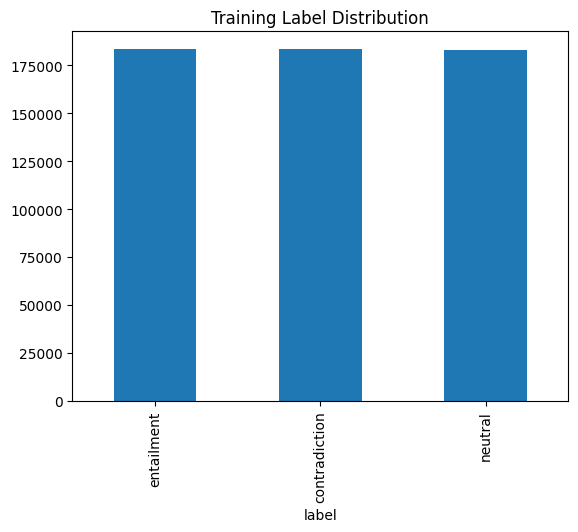

In [ ]:
# Plot per vedere quante coppie di frasi hanno le label: entailment, contradiction e neutral
stat_train_df['label'].value_counts().plot(kind='bar', title='Training Label Distribution')
plt.show()
# C'è più o meno lo stesso numero di frasi per ogni etichetta

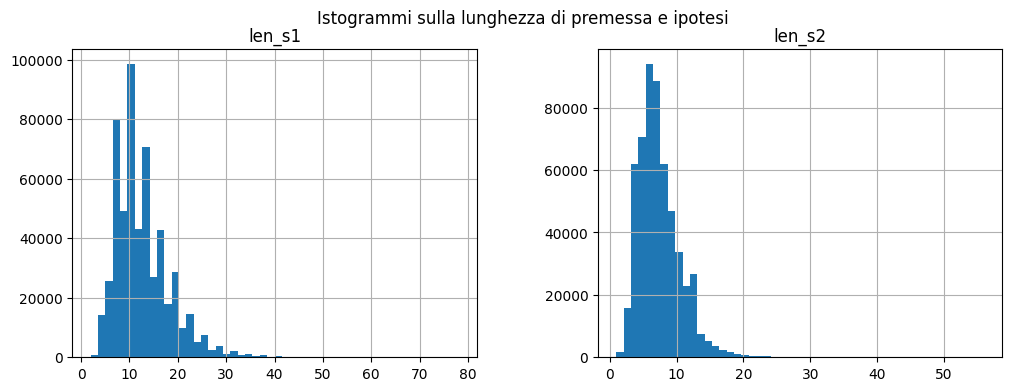

In [ ]:
# Gli istogrammi rappresentano quante frasi hanno la stessa lunghezza
stat_train_df = stat_train_df[['sentence1', 'sentence2', 'len_s1', 'len_s2', 'label']]
stat_train_df.hist(figsize=(12, 4), bins=50)
plt.suptitle("Istogrammi sulla lunghezza di premessa e ipotesi")
plt.show()

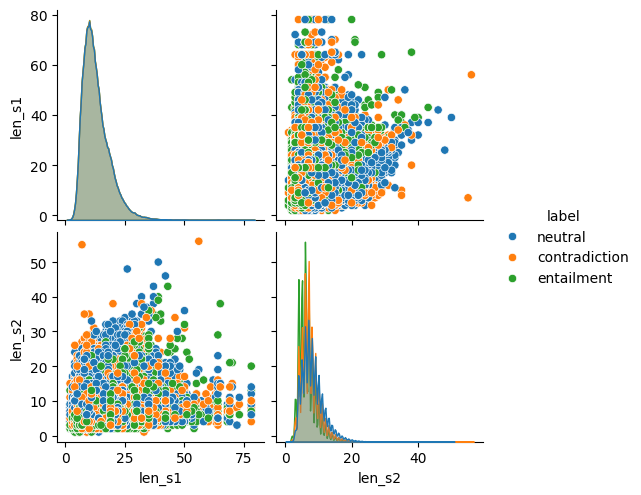

In [ ]:
# Grafici usando seaborn per capire se ci sono dipendenze fra la lunghezza delle frasi e la label
sns.pairplot(stat_train_df, hue='label')
plt.show()

Si nota che in generale, quando l'ipotesi è più lunga della premessa, è più frequente avere l'etichetta neutral. Il motivo potrebbe essere che la premessa deve contenere tutte le informazioni nell'ipotesi e quindi deve generalmente essere più lunga. La distinzione tra entailment e contradiction non sembra dipendere dalla lunghezza delle frasi:

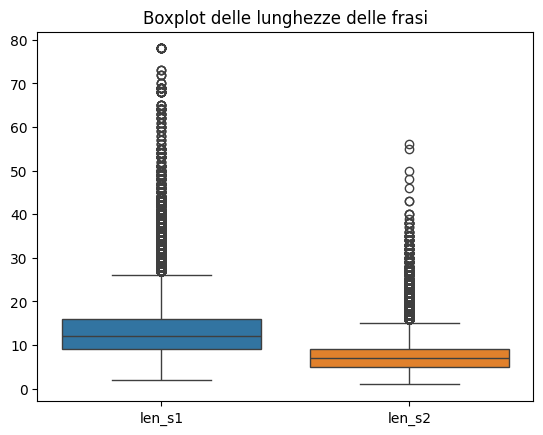

In [ ]:
# Boxplot per osservare le caratteristiche statistiche della lunghezza e del numero di caratteri delle frasi
sns.boxplot(data=stat_train_df[['len_s1', 'len_s2']])
plt.title("Boxplot delle lunghezze delle frasi")
plt.show()
# Ci sono molti outliers (valori che si distaccano di tanto dalla media)

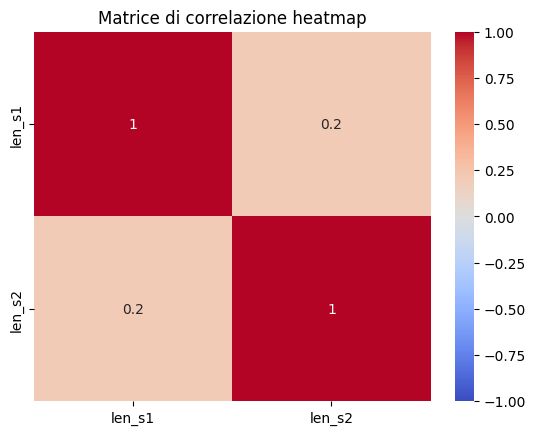

In [ ]:
# Matrice di correlazione (HEATMAP)
sns.heatmap(stat_train_df.drop(axis=1, columns=['sentence1','sentence2','label']).corr(), vmin=-1, vmax=1, annot=True, cmap='coolwarm')
plt.title("Matrice di correlazione heatmap")
plt.show()
# C'è una leggera correlazione tra la lunghezza di premessa e ipotesi

In [ ]:
# Creazione del dataframe di test, eliminando i campi nulli e le frasi corte
test_df = pd.read_csv('data/snli_1.0/snli_1.0_test.txt', sep='\t')
test_df = test_df[['sentence1', 'sentence2', 'gold_label']]
test_df = test_df.rename(columns={'gold_label': 'label'})

test_df = test_df[test_df['label'] != '-']
test_df = test_df[(test_df['sentence1'].apply(lambda x : len(x)))>4]
test_df = test_df[(test_df['sentence2'].apply(lambda x : len(x)))>4]

test_df.dropna(inplace = True)

In [ ]:
# Vediamo quanti dati ci sono nei dataframe di training e test
print("Train size:", len(train_df))
print("Test size:", len(test_df))

Train size: 549335
Test size: 9823


In [ ]:
# Definiamo una funzione per cambiare le label a {-1,0,1}
def corrispondenza(stringa):
  if stringa == 'entailment':
    return int(1)
  if stringa == 'neutral':
    return int(0)
  if stringa == 'contradiction':
    return int(-1)

In [ ]:
# Cambiamo le label di tutti i tre insiemi con cui dobbiamo lavorare
train_df['label'] = train_df['label'].apply(lambda x: corrispondenza(str(x)))
test_df['label'] = test_df['label'].apply(lambda x: corrispondenza(str(x)))

<ipython-input-23-140cf914d2ed>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df['label'] = train_df['label'].apply(lambda x: corrispondenza(str(x)))


###Tokenizzazione e creazione del vocabolario

In questa parte svolgiamo la tokenizzazione, creiamo il vocabolario, carichiamo GLove ed estraiamo le feature dalle coppie di frasi.

In [ ]:
# Funzione di Tokenizzazione
def tokenize(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = text.strip().split()  # Divide in parole
    return tokens

# Creazione dei pair
train_pairs = [(s1, s2, l) for s1, s2, l in zip(train_df['sentence1'], train_df['sentence2'], train_df['label']) if isinstance(s1, str) and isinstance(s2, str) and isinstance(l, (int, float))]
test_pairs_data = [(s1, s2, l) for s1, s2, l in zip(test_df['sentence1'], test_df['sentence2'], test_df['label']) if isinstance(s1, str) and isinstance(s2, str) and isinstance(l, (int, float))]

# Vocabolario
word_freq = {}
for sent1, sent2, _ in train_pairs:
    for word in tokenize(sent1) + tokenize(sent2): #Uniamo le frasi
        word_freq[word] = word_freq.get(word, 0) + 1

# Costruzione vocabolario
vocab = ["<pad>", "<unk>"] + sorted(word_freq.keys(), key=word_freq.get, reverse=True)
word2idx = {w: i for i, w in enumerate(vocab)}

In [ ]:
# Carichiamo GloVe
if not os.path.exists("glove.6B.zip"):
    !wget http://nlp.stanford.edu/data/glove.6B.zip
    !unzip glove.6B.zip

--2025-04-15 22:35:25--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2025-04-15 22:35:25--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2025-04-15 22:35:26--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [ ]:
embedding_dim = 300
glove_file = f"glove.6B.{embedding_dim}d.txt"
glove_embeddings = {}
with open(glove_file, 'r', encoding='utf-8') as f:
    for line in f:
        values = line.strip().split()
        word = values[0]
        vec = np.asarray(values[1:], dtype='float32')
        glove_embeddings[word] = vec

#creazione matrice embedding
embedding_matrix = np.zeros((len(vocab), embedding_dim))
for i, w in enumerate(vocab):
    if w == "<pad>":
        embedding_matrix[i] = np.zeros(embedding_dim)
    elif w in glove_embeddings:
        embedding_matrix[i] = glove_embeddings[w]
    else:
        embedding_matrix[i] = np.random.normal(scale=0.6, size=(embedding_dim,))

In [ ]:
# Funzioni embedding
def get_sentence_embedding(sentence, embedding_matrix, word2idx):
    # Tokenizza la frase
    tokens = tokenize(sentence)

    # Ottiene l'embedding per ogni parola
    word_embeddings = []
    for word in tokens:
        idx = word2idx.get(word, word2idx['<unk>'])  # Usa <unk> se la parola non è nel vocabolario
        embedding = embedding_matrix[idx]
        word_embeddings.append(embedding)

    # Se ci sono embedding validi, ritorna la media; altrimenti un vettore di zeri
    if word_embeddings:
        sentence_embedding = np.mean(word_embeddings, axis=0)
    else:
        sentence_embedding = np.zeros(embedding_matrix.shape[1])
    return sentence_embedding

In [ ]:
# Funzione per calcolare cosine similarity
def cosine_similarity(vec1, vec2):
    norm1 = np.linalg.norm(vec1)
    norm2 = np.linalg.norm(vec2)
    return np.dot(vec1, vec2) / (norm1 * norm2) if norm1 > 0 and norm2 > 0 else 0.0

#Creazione feature
def create_features(pairs):
    X, y = [], []
    for s1, s2, label in pairs:
        emb1 = get_sentence_embedding(s1, embedding_matrix, word2idx)
        emb2 = get_sentence_embedding(s2, embedding_matrix, word2idx)
        sim = cosine_similarity(emb1, emb2)
        diff = emb1 - emb2
        prod = emb1 * emb2
        features = np.concatenate([emb1, emb2, diff, prod, [sim]])
        X.append(features)
        y.append(label)
    return np.array(X), np.array(y)

X_train, y_train = create_features(train_pairs)
X_test, y_test = create_features(test_pairs_data)

###Primo modello: regressione logistica

Utilizzando X_train, Y_train... calcolati in precedenza abbiamo utilizzato la regressione logistica con dei valori esaminiti post ricerca degli iperparametri

In [ ]:
# L'addestramento del classificatore

classifier = LogisticRegression(solver='saga', penalty='l2', C=0.1, max_iter=1000)
classifier.fit(X_train, y_train)

LogisticRegression(C=0.1, max_iter=1000, solver='saga')

####Iperparametri

In [ ]:
'''
# Ricerca degli iperparametri con GridSearchCV

classifier = LogisticRegression(solver='saga', max_iter=1000)

# Definiamo i parametri da testare
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
}

grid_search = GridSearchCV(
    estimator=classifier,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    verbose=1,
    n_jobs=1 # Con n_jobs=-1 terminava subito e dava l'errore
)
grid_search.fit(X_train, y_train)
print(grid_search.best_params_) # Vediamo i parametri migliori trovati
'''

"\n# Ricerca degli iperparametri con GridSearchCV\n\nclassifier = LogisticRegression(solver='saga', max_iter=1000)\n\n# Definiamo i parametri da testare\nparam_grid = {\n    'C': [0.01, 0.1, 1, 10],\n    'penalty': ['l1', 'l2'],\n}\n\ngrid_search = GridSearchCV(\n    estimator=classifier,\n    param_grid=param_grid,\n    scoring='accuracy',\n    cv=5,\n    verbose=1,\n    n_jobs=1 # Con n_jobs=-1 terminava subito e dava l'errore\n)\ngrid_search.fit(X_train, y_train)\nprint(grid_search.best_params_) # Vediamo i parametri migliori trovati\n"

Abbiamo eseguito il codice sopra su 50000 dati (su tutti i dati impiegava troppo tempo e si interrompeva il runtime) e ci ha restituito {penalty = 'l1', C = 10}.

Abbiamo visto che i risultati con una penalty l2 cambiano pochissimo rispetto alla penalty l1; tuttavia il codice con l2 impiega molto meno tempo e perciò abbiamo deciso di sceglierla.

Invece per C abbiamo scelto 0.1 perchè la discesa della loss si vede meglio nelle prime epoche rispetto a C = 10.

####Loss

In questa parte, calcoliamo prima la loss finale dopo l'addestramento e nella cella dopo mostriamo la discesa di loss nelle prime 10 epoche per far vedere che sta scendendo e che il modello funziona.

In [ ]:
# Calcoliamo la loss finale dopo 1000 iterazioni
probs = classifier.predict_proba(X_train)
loss = log_loss(y_train, probs)
loss

0.8442026957442282

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Epoch 1, Loss: 0.8691


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Epoch 2, Loss: 0.8896


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


...

Epoch 8, Loss: 0.8610


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Epoch 9, Loss: 0.8633


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Epoch 10, Loss: 0.8807


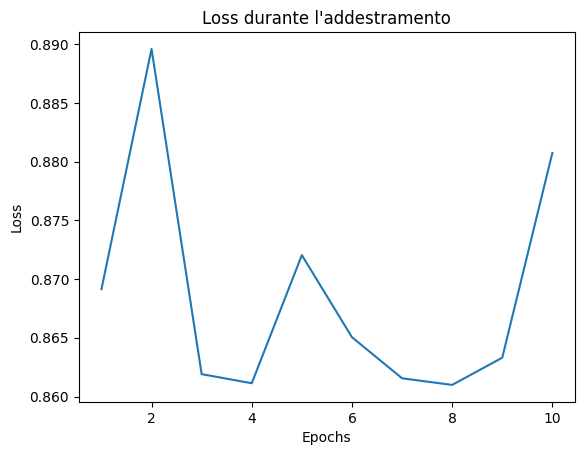

In [ ]:
# Vediamo come si comporta la loss durante le prime 20 epoche dell’addestramento

classifier = LogisticRegression(solver='saga', penalty='l2', C=0.1, max_iter=1)
losses = []

for epoch in range(10):
    classifier.fit(X_train, y_train)
    probs = classifier.predict_proba(X_train)
    loss = log_loss(y_train, probs)
    losses.append(loss)
    print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

# Vediamo il suo comportamento in un grafico

plt.plot(range(1, len(losses)+1), losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss durante l'addestramento")
plt.show()

####Test

Qui abbiamo deciso di stampare 10 frasi e far vedere se le predice nella maniera corretta.

In [ ]:
y_pred = classifier.predict(X_test)

# Funzione per decodificare la label
def decodifica_label(num):
   return {1: 'entailment', 0: 'neutral', -1: 'contradiction'}.get(num, 'unknown')

# Vediamo come si comporta il modello sulle prime 10 coppie di frasi
print("\nEsempi di predizione sul test set:\n")
for i in range(10):
    sent1, sent2 = test_pairs_data[i][0], test_pairs_data[i][1]
    true_label = y_test[i]
    pred_label = y_pred[i]

    print(f"Frase 1: {sent1}")
    print(f"Frase 2: {sent2}")
    print(f"Etichetta reale: {decodifica_label(true_label)}")
    print(f"Etichetta predetta: {decodifica_label(pred_label)}")
    print("Risultato:", "✅ Corretto" if true_label == pred_label else "❌ Errato")
    print("-" * 80)


Esempi di predizione sul test set:

Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: The church has cracks in the ceiling.
Etichetta reale: neutral
Etichetta predetta: contradiction
Risultato: ❌ Errato
--------------------------------------------------------------------------------
Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: The church is filled with song.
Etichetta reale: entailment
Etichetta predetta: neutral
Risultato: ❌ Errato
--------------------------------------------------------------------------------
Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: A choir singing at a baseball game.
Etichetta reale: contradiction
Etichetta predetta: contradiction
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: A woman with a green headscarf, blue

In [ ]:
# Vediamo quanto ha predetto giustamente in totale delle coppie in test
print(f"Totale frasi corrette: {(y_pred == y_test).sum()} su {len(y_test)}")

Totale frasi corrette: 6086 su 9823


####Metriche di valutazione

In questa parte valutiamo il modello con le seguenti metriche di valutazione:
* Accuracy, Accuracy bilanciata
* Precision, Recall, F1-Score
* Confusion matrix
* Classification report

In [ ]:
# decodifichiamo la lista delle label da numeri a stringhe
y_true =[]
y_predict = []

for y_t, y_p in zip(y_test, y_pred):
  y_true.append (decodifica_label(y_t))
  y_predict.append (decodifica_label(y_p))

In [ ]:
# La lista delle label per usare in metriche di valutazione
etichette = ['entailment', 'neutral', 'contradiction']

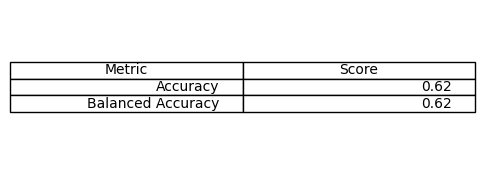

In [ ]:
#ACCURACY

#Calcoliamo l'accuracy di tutte le classi in totale:
acc = accuracy_score(y_test, y_pred)

#Calcoliamo l'accuracy bilanciata (calcola l'accuracy score di ogni classe separatamente e poi fa la media):
balanced_acc = balanced_accuracy_score(y_test, y_pred)

#Creiamo la tabella per l'accuracy
fig, ax = plt.subplots(1, 1, figsize=(6, 2))
ax.axis('tight')
ax.axis('off')
table_data = [['Accuracy', f'{acc:.2f}'], ['Balanced Accuracy', f'{balanced_acc:.2f}']]
table = ax.table(cellText=table_data, colLabels=['Metric', 'Score'], loc='center')

plt.show()

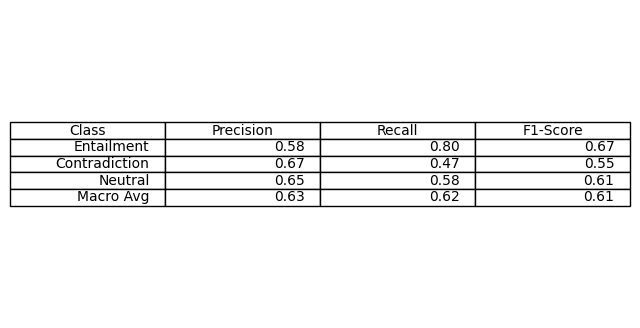

In [ ]:
 #PRECISION, RECALL, F1SCORE

#Calcoliamo l'array di precision score di tutte le classi:
precision_arr = precision_score(y_true, y_predict, labels=etichette, average=None)

#Calcoliamo precision score in media:
precision_mean = precision_score(y_true, y_predict, labels=etichette, average='macro')

#Facciamo la stessa cosa con recall e F1_Score:
recall_arr = recall_score(y_true, y_predict, labels=etichette, average=None)
recall_mean = recall_score(y_true, y_predict, labels=etichette, average='macro')

F1_Score_arr = f1_score(y_true, y_predict, labels=etichette, average=None)
F1_Score_mean = f1_score(y_true, y_predict, labels=etichette, average='macro')

# Creiamo la tabella per precision, recall, e F1-score
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.axis('tight')
ax.axis('off')
table_data = [
    ['Entailment', f'{precision_arr[0]:.2f}', f'{recall_arr[0]:.2f}', f'{F1_Score_arr[0]:.2f}'],
    ['Contradiction', f'{precision_arr[1]:.2f}', f'{recall_arr[1]:.2f}', f'{F1_Score_arr[1]:.2f}'],
    ['Neutral', f'{precision_arr[2]:.2f}', f'{recall_arr[2]:.2f}', f'{F1_Score_arr[2]:.2f}'],
    ['Macro Avg', f'{precision_mean:.2f}', f'{recall_mean:.2f}', f'{F1_Score_mean:.2f}']
]
table = ax.table(cellText=table_data, colLabels=['Class', 'Precision', 'Recall', 'F1-Score'], loc='center')

plt.show()

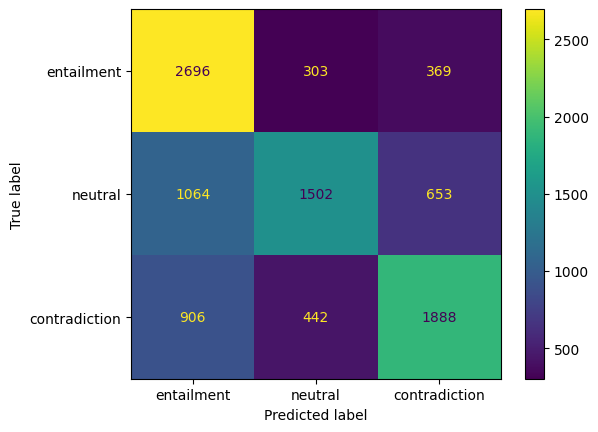

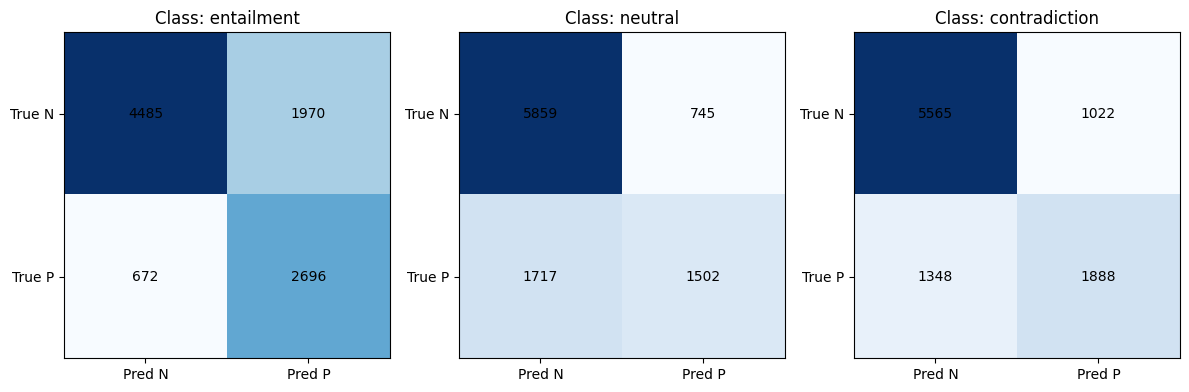

In [ ]:
#CONFUSION MATRIX

#Facciamo la matrice di confusione per tutte e tre classi insieme:
conf_matrix = confusion_matrix(y_true, y_predict, labels=etichette, sample_weight=None, normalize=None)

#Display di matrice di confusione:
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=etichette)
disp.plot()
plt.show()

#Possiamo anche creare matrici di confusione per ognuno di classi separatamente
conf_matrices = multilabel_confusion_matrix(y_true, y_predict, labels=etichette)

#Plottare ogni 2x2 confusion matrix:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))  #una riga e tre colonne per tre classi

for i, (label, matrix) in enumerate(zip(etichette, conf_matrices)):
    ax = axes[i]
    im = ax.imshow(matrix, cmap='Blues')

    #aggiungiamo i valori dentro le matrici:
    for (j, k), value in np.ndenumerate(matrix):
        ax.text(k, j, str(value), ha='center', va='center', color='black')

    ax.set_title(f'Class: {label}')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred N', 'Pred P'])
    ax.set_yticklabels(['True N', 'True P'])

plt.tight_layout()
plt.show()

In [ ]:
#CLASSIFICATION REPORT

#Calcoliamo classification report:
class_rep = classification_report(y_true, y_predict, labels=etichette, target_names=etichette)
print(class_rep)

               precision    recall  f1-score   support

   entailment       0.58      0.80      0.67      3368
      neutral       0.67      0.47      0.55      3219
contradiction       0.65      0.58      0.61      3236

     accuracy                           0.62      9823
    macro avg       0.63      0.62      0.61      9823
 weighted avg       0.63      0.62      0.61      9823



###Secondo modello: MLP

Per questo secondo modello abbiamo sempre utilizzato X_train, Y_train... calcolate in precedenza ma questo volta abbiamo applicato un MLP

In [ ]:
# MLP Classifier
mlp = MLPClassifier(hidden_layer_sizes=(256, 128), activation='relu', solver='adam', max_iter=1, warm_start=True)

####Iperparametri

In [ ]:
'''# Grid Search
param_grid = {
    'hidden_layer_sizes': [(64,),(128,), (256, 128), (512, 256)],
    'activation': ['tanh', 'relu'],
    'alpha': [0.0001, 0.001, 0.01, 0.00001],
    'learning_rate_init': [0.001, 0.01, 0.00005, 0.0001]
}

mlp = MLPClassifier(max_iter=20, solver='adam')
grid_search = GridSearchCV(mlp, param_grid, cv=3, scoring='neg_log_loss', verbose=2, n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Migliori iperparametri trovati:")
print(grid_search.best_params_)

print("\nLoss negativa media (cross-validation):")
print(-grid_search.best_score_)'''

'# Grid Search\nparam_grid = {\n    \'hidden_layer_sizes\': [(64,),(128,), (256, 128), (512, 256)],\n    \'activation\': [\'tanh\', \'relu\'],\n    \'alpha\': [0.0001, 0.001, 0.01, 0.00001],\n    \'learning_rate_init\': [0.001, 0.01, 0.00005, 0.0001]\n}\n\nmlp = MLPClassifier(max_iter=20, solver=\'adam\')\ngrid_search = GridSearchCV(mlp, param_grid, cv=3, scoring=\'neg_log_loss\', verbose=2, n_jobs=-1)\ngrid_search.fit(X_train, y_train)\n\nprint("Migliori iperparametri trovati:")\nprint(grid_search.best_params_)\n\nprint("\nLoss negativa media (cross-validation):")\nprint(-grid_search.best_score_)'

La ricerca degli iperparametri ci ha dato in output: {'activation': 'relu', 'alpha': 1e-05, 'hidden_layer_sizes': (256, 128), 'learning_rate_init': 0.0001}. Con questi iperparametri l'accuratezza diventa 0.764 e la loss 0.491

####Loss

Visualizziamo i primi 5 valori della funzione di loss e tracciamo un grafico per evidenziarne la progressiva diminuzione nel corso dell’addestramento.

Se si estende l’addestramento fino a 20 epoche, si osserva un progressivo miglioramento delle prestazioni, con l’accuracy che raggiunge un valore di circa 0.41.

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch 1, Loss: 0.6789


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch 2, Loss: 0.6228


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch 3, Loss: 0.5996


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch 4, Loss: 0.5673


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch 5, Loss: 0.5531


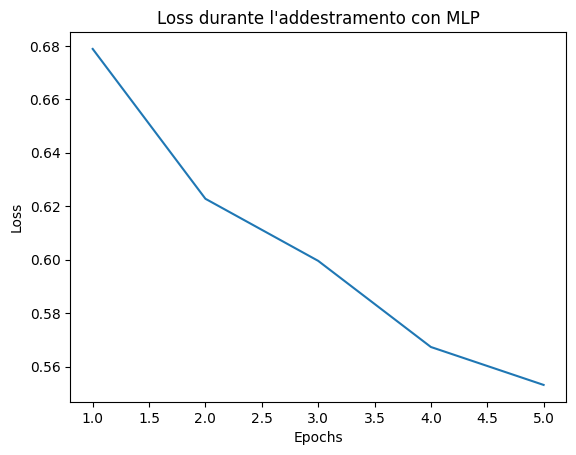

In [ ]:
losses = []

for epoch in range(5):
    mlp.fit(X_train, y_train)
    probs = mlp.predict_proba(X_train)
    loss = log_loss(y_train, probs)
    losses.append(loss)
    print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

# Plot della loss
plt.plot(range(1, 6), losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss durante l'addestramento con MLP")
plt.show()

In [ ]:
probs = mlp.predict_proba(X_train)
loss = log_loss(y_train, probs)  # Calcola il log loss finale
print("Log Loss (train):", loss)

Log Loss (train): 0.5531202398441721


####Test

E come nel primo modello abbiamo deciso di far vedere su 10 frasi se il modello predice bene la tipologia di relazione tra le due frasi

In [ ]:
# Test del modello
y_pred = mlp.predict(X_test)

print("\nEsempi di predizione sul test set:\n")
for i in range(10):
   s1, s2 = test_pairs_data[i][0], test_pairs_data[i][1]
   true_label = y_test[i]
   pred_label = y_pred[i]

   print(f"Frase 1: {s1}")
   print(f"Frase 2: {s2}")
   print(f"Etichetta reale: {decodifica_label(true_label)}")
   print(f"Etichetta predetta: {decodifica_label(pred_label)}")
   print("Risultato:", "✅ Corretto" if true_label == pred_label else "❌ Errato")
   print("-" * 80)


Esempi di predizione sul test set:

Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: The church has cracks in the ceiling.
Etichetta reale: neutral
Etichetta predetta: neutral
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: The church is filled with song.
Etichetta reale: entailment
Etichetta predetta: entailment
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: A choir singing at a baseball game.
Etichetta reale: contradiction
Etichetta predetta: contradiction
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: A woman with a green headscarf, blu

In [ ]:
print(f"Totale frasi corrette: {(y_pred == y_test).sum()} su {len(y_test)}")

Totale frasi corrette: 7380 su 9823


####Metriche di valutazione

In questa parte valutiamo il modello con le seguenti metriche di valutazione:
* Accuracy, Accuracy bilanciata
* Precision, Recall, F1-Score
* Confusion matrix
* Classification report

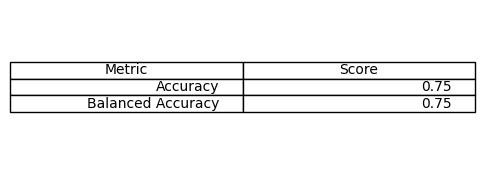

In [ ]:
#ACCURACY

#Calcoliamo l'accuracy di tutte le classi in totale:
acc = accuracy_score(y_test, y_pred)

#Calcoliamo l'accuracy bilanciata (calcola l'accuracy score di ogni classe separatamente e poi fa la media):
balanced_acc = balanced_accuracy_score(y_test, y_pred)

#Creiamo la tabella per l'accuracy
fig, ax = plt.subplots(1, 1, figsize=(6, 2))
ax.axis('tight')
ax.axis('off')
table_data = [['Accuracy', f'{acc:.2f}'], ['Balanced Accuracy', f'{balanced_acc:.2f}']]
table = ax.table(cellText=table_data, colLabels=['Metric', 'Score'], loc='center')

plt.show()

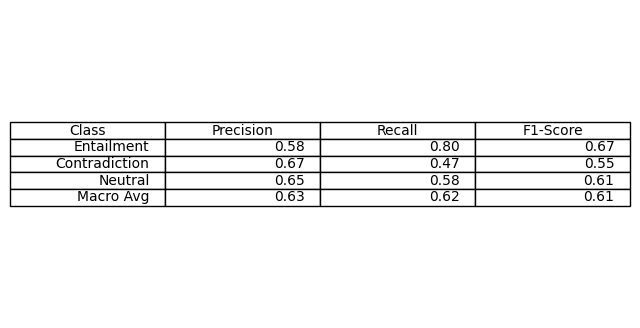

In [ ]:
#PRECISION, RECALL, F1SCORE

#Calcoliamo l'array di precision score di tutte le classi:
precision_arr = precision_score(y_true, y_predict, labels=etichette, average=None)

#Calcoliamo precision score in media:
precision_mean = precision_score(y_true, y_predict, labels=etichette, average='macro')

#Facciamo la stessa cosa con recall e F1_Score:
recall_arr = recall_score(y_true, y_predict, labels=etichette, average=None)
recall_mean = recall_score(y_true, y_predict, labels=etichette, average='macro')

F1_Score_arr = f1_score(y_true, y_predict, labels=etichette, average=None)
F1_Score_mean = f1_score(y_true, y_predict, labels=etichette, average='macro')

# Creiamo la tabella per precision, recall, e F1-score
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.axis('tight')
ax.axis('off')
table_data = [
    ['Entailment', f'{precision_arr[0]:.2f}', f'{recall_arr[0]:.2f}', f'{F1_Score_arr[0]:.2f}'],
    ['Contradiction', f'{precision_arr[1]:.2f}', f'{recall_arr[1]:.2f}', f'{F1_Score_arr[1]:.2f}'],
    ['Neutral', f'{precision_arr[2]:.2f}', f'{recall_arr[2]:.2f}', f'{F1_Score_arr[2]:.2f}'],
    ['Macro Avg', f'{precision_mean:.2f}', f'{recall_mean:.2f}', f'{F1_Score_mean:.2f}']
]
table = ax.table(cellText=table_data, colLabels=['Class', 'Precision', 'Recall', 'F1-Score'], loc='center')

plt.show()

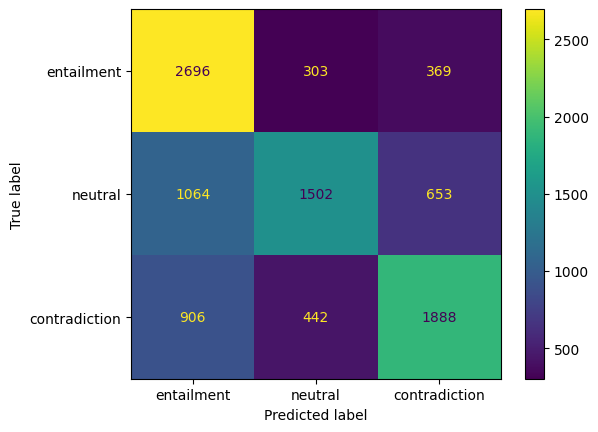

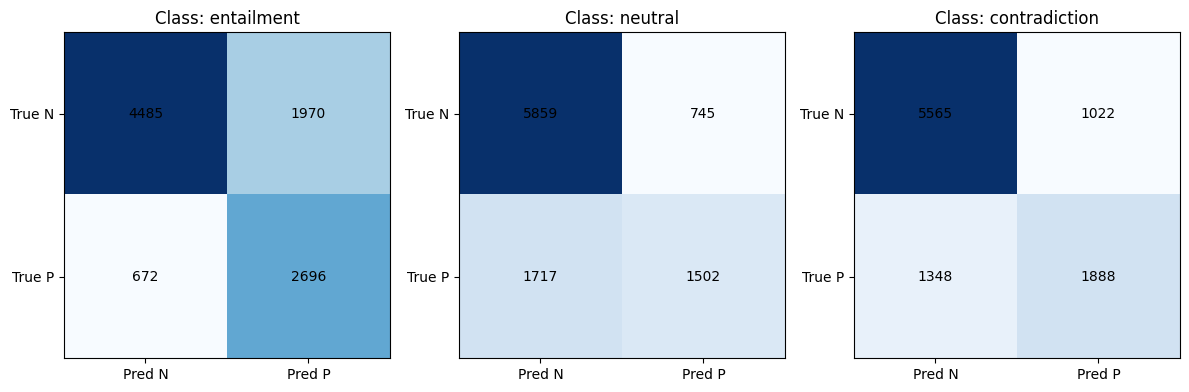

In [ ]:
#CONFUSION MATRIX

#Facciamo display della matrice di confusione per tutte e tre classi insieme, prendendo i dati necessari direttamente dalle predizioni:
ConfusionMatrixDisplay.from_predictions(y_true, y_predict, labels=etichette)
plt.show()

#Creiamo la matrice di confusione 2x2 per ciascuna classe separatamente:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))  #una riga e tre colonne per tre classi

for i, label in enumerate(etichette):
    ax = axes[i]

    #Estraiamo la matrice di confusione 2x2 per la classe corrente
    binary_true = [1 if item == label else 0 for item in y_true]
    binary_pred = [1 if item == label else 0 for item in y_predict]

    matrix = confusion_matrix(binary_true, binary_pred)

    im = ax.imshow(matrix, cmap='Blues')

    #Aggiungiamo i valori dentro le matrici:
    for (j, k), value in np.ndenumerate(matrix):
        ax.text(k, j, str(value), ha='center', va='center', color='black')

    ax.set_title(f'Class: {label}')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred N', 'Pred P'])
    ax.set_yticklabels(['True N', 'True P'])

plt.tight_layout()
plt.show()

In [ ]:
#CLASSIFICATION REPORT

#Calcoliamo classification report:
class_rep = classification_report(y_true, y_predict, labels=etichette, target_names=etichette)
print(class_rep)

               precision    recall  f1-score   support

   entailment       0.58      0.80      0.67      3368
      neutral       0.67      0.47      0.55      3219
contradiction       0.65      0.58      0.61      3236

     accuracy                           0.62      9823
    macro avg       0.63      0.62      0.61      9823
 weighted avg       0.63      0.62      0.61      9823



###Versione con LSTM

Durante il progetto abbiamo anche implementato una versione avanzata del classificatore che combina un LSTM con un MLP e feature ingegnerizzate. Tuttavia, a causa della complessità del modello e delle limitazioni computazionali (esecuzione su CPU), le sue prestazioni si sono rivelate inferiori rispetto a un MLP più semplice ma ben ottimizzato. Abbiamo quindi deciso di utilizzare il modello MLP finale come soluzione migliore.

Le **feature ingegnerizzate** come la differenza assoluta |u - v|, il prodotto elemento per elemento u * v e la similarità coseno cos_sim(u, v) permettono di catturare in modo esplicito le relazioni semantiche tra due frasi, evidenziandone le differenze, le interazioni dirette e il grado di somiglianza nel significato.

In [ ]:
'''# --- DATASET PERSONALIZZATO ---
class SentencePairsDataset(Dataset):
    def __init__(self, df, word2idx, max_len=100, embedding_model=None):
        # Inizializza una lista vuota per memorizzare i dati
        self.data = []
        self.embedding_model = embedding_model
        # Scorri attraverso il DataFrame con le coppie di frasi e le etichette.
        for s1, s2, label in zip(df['sentence1'], df['sentence2'], df['label']):
            t1 = self.encode(self.tokenize(s1), word2idx, max_len)
            t2 = self.encode(self.tokenize(s2), word2idx, max_len)
            label = self.map_label(label)
            self.data.append((t1, t2, label))

    def tokenize(self, sentence):
        # Converte la frase in minuscolo e la divide in parole
        return str(sentence).lower().split()

    def encode(self, tokens, word2idx, max_len):
        # Converte i token in indici, usa <unk> per parole sconosciute
        idxs = [word2idx.get(w, word2idx['<unk>']) for w in tokens]
        # Tronca o riempie con <pad> per ottenere lunghezza fissa
        return idxs[:max_len] + [word2idx['<pad>']] * (max_len - len(idxs[:max_len]))

    def map_label(self, label):
        return {-1: 0, 0: 1, 1: 2}.get(label, 1)

    def __len__(self):
        # Restituisce la lunghezza del dataset
        return len(self.data)

    def __getitem__(self, idx):
        # Restituisce le frasi codificate e l'etichetta come tensori
        s1_idxs, s2_idxs, label = self.data[idx]
        return torch.tensor(s1_idxs), torch.tensor(s2_idxs), torch.tensor(label)

# --- MODELLO LSTM + MLP CON FEATURE INGEGNERIZZATE ---
class LSTMwithMLP(pl.LightningModule):
    def __init__(self, embedding_matrix, hidden_dim=128, mlp_dim=64, output_dim=3):
        super().__init__()
        # Usa torch.tensor per convertire l'array NumPy in un tensore PyTorch
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix, dtype=torch.float32), freeze=True)
        #Definisce un LSTM con embedding di dimensione
           'embedding_matrix.shape[1]', un layer,
           dropout del 50% e senza bidirezionalità.
        self.lstm = nn.LSTM(
            embedding_matrix.shape[1], hidden_dim,
            batch_first=True, num_layers=1,
            dropout=0.5, bidirectional=False
        )
        # Calcola la dimensione delle feature per l'input del MLP:
        #4 * hidden_dim (dai 4 tipi di feature) + 1 per la cosine similarity
        feature_dim = 4 * hidden_dim + 1
        #Definisce una rete MLP composta da:
          #1. Un layer lineare che mappa 'feature_dim' in 'mlp_dim'
          #2. Una funzione di attivazione ReLU
          #3. Un layer di dropout con probabilità 0.3 per evitare overfitting
          #4. Un altro layer lineare che mappa 'mlp_dim' nell'output finale
        self.mlp = nn.Sequential(
            nn.Linear(feature_dim, mlp_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(mlp_dim, output_dim)
        )
    #Passa le frasi attraverso LSTM per ottenere le rappresentazioni,
    #poi estrae caratteristiche come max pooling, differenza,
    #prodotto e similarità coseno. Le caratteristiche vengono concatenate e
    #passate attraverso un MLP per ottenere la previsione finale.
    def forward(self, s1, s2):
        e1, _ = self.lstm(self.embedding(s1))
        e2, _ = self.lstm(self.embedding(s2))
        u = torch.max(e1, dim=1)[0]
        v = torch.max(e2, dim=1)[0]
        diff = torch.abs(u - v)
        prod = u * v
        cos = F.cosine_similarity(u, v).unsqueeze(1)
        features = torch.cat([u, v, diff, prod, cos], dim=1)
        return self.mlp(features)

    #Calcola la previsione del modello, la loss e l'accuratezza
    #durante il training, poi registra la loss e l'accuratezza nel logger
    #per il monitoraggio del progresso.
    def training_step(self, batch, batch_idx):
        s1, s2, labels = batch
        preds = self(s1, s2)
        loss = F.cross_entropy(preds, labels)
        acc = (preds.argmax(dim=1) == labels).float().mean()
        self.log("train_loss", loss, prog_bar=True)
        self.log("train_acc", acc, prog_bar=True)
        return loss

    #Calcola la previsione del modello, la loss e l'accuratezza
    #durante la validazione, poi registra la loss e l'accuratezza nel logger
    #per il monitoraggio del progresso.
    def validation_step(self, batch, batch_idx):
        s1, s2, labels = batch
        preds = self(s1, s2)
        loss = F.cross_entropy(preds, labels)
        acc = (preds.argmax(dim=1) == labels).float().mean()
        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)

    #Configura l'ottimizzatore AdamW con un tasso di apprendimento di 1e-3
    #e un scheduler che riduce il tasso di apprendimento quando la 'val_loss'
    #non migliora per 3 epoche consecutive.
    #Restituisce l'ottimizzatore e lo scheduler insieme all'indicazione
    #su quale metrica monitorare.
    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(), lr=1e-3)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3)
        return {"optimizer": optimizer, "lr_scheduler": scheduler, "monitor": "val_loss"}

# --- FUNZIONE DECODIFICA LABEL ---
def decodifica_label(label):
    return {0: -1, 1: 0, 2: 1}.get(label, "Unknown")

# --- CREAZIONE MATRICE DI EMBEDDING ---
# glove_embeddings è un dizionario con parole come chiavi e gli embedding come valori.
# Supponiamo che gli embeddings siano di dimensione 100
embedding_matrix = np.zeros((len(word2idx), 100))
for word, idx in word2idx.items():
    if word in glove_embeddings:
        embedding_matrix[idx] = glove_embeddings[word]
    else:
        # Embedding casuale per parole non trovate
        embedding_matrix[idx] = np.random.randn(100)

# --- CREAZIONE DATASET & DATALOADER ---

# Crea il dataset per il training usando il DataFrame e il vocabolario
train_dataset = SentencePairsDataset(train_df, word2idx, embedding_model=glove_embeddings)
# Crea il dataset per il test/validazione con le stesse impostazioni
test_dataset = SentencePairsDataset(test_df, word2idx, embedding_model=glove_embeddings)
# Crea il DataLoader per il training con shuffle per mescolare i dati ad ogni epoca
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
# Crea il DataLoader per il test/validazione senza shuffle
test_loader = DataLoader(test_dataset, batch_size=32)

# --- CALLBACKS ---
early_stop = EarlyStopping(
    monitor='val_loss', # Osserva la validation loss
    patience=3, # Ferma l'addestramento se non migliora per 3 epoche
    verbose=True,  # Stampa messaggi quando si attiva l'early stopping
    mode='min' # Minimizza la metrica monitorata
)
checkpoint = ModelCheckpoint(
    monitor='val_loss', # Salva il modello migliore in base alla val_loss
    dirpath='checkpoints', # Cartella dove salvare il modello
    filename='best-lstm-mlp', # Nome del file del modello salvato
    save_top_k=1,  # Salva solo il modello con la miglior val_loss
    mode='min',
    verbose=True
)
logger = TensorBoardLogger(
    "tb_logs",   # Cartella dove salvare i log
    name="lstm_mlp"  # Nome della sessione di logging
)

# --- TRAINING ---
# Inizializza il modello LSTM con MLP usando la matrice
# di embedding pre-addestrata
model = LSTMwithMLP(embedding_matrix=embedding_matrix)
trainer = pl.Trainer(
    max_epochs=15, # Numero massimo di epoche di addestramento
    logger=logger,  # Logger per visualizzare metriche in TensorBoard
    enable_checkpointing=True, # Abilita il salvataggio del modello migliore
    callbacks=[early_stop, checkpoint],  # Usa early stopping e checkpoint per salvare il modello
    accelerator="cpu", # Usa la CPU per l’addestramento
)

# Avvia l’addestramento del modello con i dati di training e validazione
trainer.fit(model, train_loader, val_dataloaders=test_loader)

# --- VALUTAZIONE ---
model.eval()
all_preds, all_labels = [], []
correct = 0
for s1, s2, labels in test_loader:
    # Disabilita il calcolo dei gradienti durante la valutazione
    with torch.no_grad():
        logits = model(s1, s2)
        # Predizioni dal modello
        preds = torch.argmax(logits, dim=1)
        # Aggiungi le predizioni alla lista
        all_preds.extend(preds.tolist())
        # Aggiungi le etichette vere alla lista
        all_labels.extend(labels.tolist())
        correct += (preds == labels).sum().item()

# --- STAMPA 10 ESEMPI ---
print("\n--- LSTM + MLP ---")
for i in range(10):
    print(f"Frase 1: {test_df.iloc[i]['sentence1']}")
    print(f"Frase 2: {test_df.iloc[i]['sentence2']}")
    print(f"Etichetta reale: {decodifica_label(all_labels[i])}")
    print(f"Etichetta predetta: {decodifica_label(all_preds[i])}")
    print("Risultato:", "✅ Corretto" if all_labels[i] == all_preds[i] else "❌ Errato")
    print("-" * 80)

# --- ACCURATEZZA TOTALE ---
print(f"Accuratezza totale: {correct} / {len(all_labels)} = {correct / len(all_labels):.2%}")'''


'# --- DATASET PERSONALIZZATO ---\nclass SentencePairsDataset(Dataset):\n    def __init__(self, df, word2idx, max_len=100, embedding_model=None):\n        # Inizializza una lista vuota per memorizzare i dati\n        self.data = []\n        self.embedding_model = embedding_model\n        # Scorri attraverso il DataFrame con le coppie di frasi e le etichette.\n        for s1, s2, label in zip(df[\'sentence1\'], df[\'sentence2\'], df[\'label\']):\n            t1 = self.encode(self.tokenize(s1), word2idx, max_len)\n            t2 = self.encode(self.tokenize(s2), word2idx, max_len)\n            label = self.map_label(label)\n            self.data.append((t1, t2, label))\n\n    def tokenize(self, sentence):\n        # Converte la frase in minuscolo e la divide in parole\n        return str(sentence).lower().split()\n\n    def encode(self, tokens, word2idx, max_len):\n        # Converte i token in indici, usa <unk> per parole sconosciute\n        idxs = [word2idx.get(w, word2idx[\'<unk>\']) 

output: INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.callbacks.model_summary:
  | Name      | Type       | Params | Mode
-------------------------------------------------
0 | embedding | Embedding  | 3.5 M  | train
1 | lstm      | LSTM       | 117 K  | train
2 | mlp       | Sequential | 33.1 K | train
-------------------------------------------------
150 K     Trainable params
3.5 M     Non-trainable params
3.7 M     Total params
14.794    Total estimated model params size (MB)
7         Modules in train mode
0         Modules in eval mode
Sanity Checking: |          | 0/? [00:00<?, ?it/s]
Training: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.callbacks.early_stopping:Metric val_loss improved. New best score: 0.704
INFO:pytorch_lightning.utilities.rank_zero:Epoch 0, global step 17168: 'val_loss' reached 0.70425 (best 0.70425), saving model to '/content/checkpoints/best-lstm-mlp.ckpt' as top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.callbacks.early_stopping:Metric val_loss improved by 0.039 >= min_delta = 0.0. New best score: 0.666
INFO:pytorch_lightning.utilities.rank_zero:Epoch 1, global step 34336: 'val_loss' reached 0.66553 (best 0.66553), saving model to '/content/checkpoints/best-lstm-mlp.ckpt' as top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.callbacks.early_stopping:Metric val_loss improved by 0.012 >= min_delta = 0.0. New best score: 0.654
INFO:pytorch_lightning.utilities.rank_zero:Epoch 2, global step 51504: 'val_loss' reached 0.65379 (best 0.65379), saving model to '/content/checkpoints/best-lstm-mlp.ckpt' as top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.callbacks.early_stopping:Metric val_loss improved by 0.006 >= min_delta = 0.0. New best score: 0.648
INFO:pytorch_lightning.utilities.rank_zero:Epoch 3, global step 68672: 'val_loss' reached 0.64791 (best 0.64791), saving model to '/content/checkpoints/best-lstm-mlp.ckpt' as top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.utilities.rank_zero:Epoch 4, global step 85840: 'val_loss' was not in top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.callbacks.early_stopping:Metric val_loss improved by 0.009 >= min_delta = 0.0. New best score: 0.639
INFO:pytorch_lightning.utilities.rank_zero:Epoch 5, global step 103008: 'val_loss' reached 0.63883 (best 0.63883), saving model to '/content/checkpoints/best-lstm-mlp.ckpt' as top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.utilities.rank_zero:Epoch 6, global step 120176: 'val_loss' was not in top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.callbacks.early_stopping:Metric val_loss improved by 0.011 >= min_delta = 0.0. New best score: 0.628
INFO:pytorch_lightning.utilities.rank_zero:Epoch 7, global step 137344: 'val_loss' reached 0.62776 (best 0.62776), saving model to '/content/checkpoints/best-lstm-mlp.ckpt' as top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.utilities.rank_zero:Epoch 8, global step 154512: 'val_loss' was not in top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.utilities.rank_zero:Epoch 9, global step 171680: 'val_loss' was not in top 1
Validation: |          | 0/? [00:00<?, ?it/s]
INFO:pytorch_lightning.callbacks.early_stopping:Monitored metric val_loss did not improve in the last 3 records. Best score: 0.628. Signaling Trainer to stop.
INFO:pytorch_lightning.utilities.rank_zero:Epoch 10, global step 188848: 'val_loss' was not in top 1

--- LSTM + MLP ---
Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: The church has cracks in the ceiling.
Etichetta reale: 0
Etichetta predetta: 0
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: The church is filled with song.
Etichetta reale: 1
Etichetta predetta: 0
Risultato: ❌ Errato
--------------------------------------------------------------------------------
Frase 1: This church choir sings to the masses as they sing joyous songs from the book at a church.
Frase 2: A choir singing at a baseball game.
Etichetta reale: -1
Etichetta predetta: -1
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: A woman with a green headscarf, blue shirt and a very big grin.
Frase 2: The woman is young.
Etichetta reale: 0
Etichetta predetta: 1
Risultato: ❌ Errato
--------------------------------------------------------------------------------
Frase 1: A woman with a green headscarf, blue shirt and a very big grin.
Frase 2: The woman is very happy.
Etichetta reale: 1
Etichetta predetta: 1
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: A woman with a green headscarf, blue shirt and a very big grin.
Frase 2: The woman has been shot.
Etichetta reale: -1
Etichetta predetta: 0
Risultato: ❌ Errato
--------------------------------------------------------------------------------
Frase 1: An old man with a package poses in front of an advertisement.
Frase 2: A man poses in front of an ad.
Etichetta reale: 1
Etichetta predetta: 1
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: An old man with a package poses in front of an advertisement.
Frase 2: A man poses in front of an ad for beer.
Etichetta reale: 0
Etichetta predetta: 0
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: An old man with a package poses in front of an advertisement.
Frase 2: A man walks by an ad.
Etichetta reale: -1
Etichetta predetta: -1
Risultato: ✅ Corretto
--------------------------------------------------------------------------------
Frase 1: A statue at a museum that no seems to be looking at.
Frase 2: The statue is offensive and people are mad that it is on display.
Etichetta reale: 0
Etichetta predetta: -1
Risultato: ❌ Errato
--------------------------------------------------------------------------------
Accuratezza totale: 7276 / 9824 = 74.06%

###Conclusioni: Fonti


TensorBoardLogger:
https://lightning.ai/docs/pytorch/stable/extensions/generated/lightning.pytorch.loggers.TensorBoardLogger.html

EarlyStopping:
https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.callbacks.EarlyStopping.html

ModelCheckpoint:
https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.callbacks.ModelCheckpoint.html

Feature ingegnerizzate:
*Supervised Learning of Universal Sentence Representations from Natural Language Inference Data (pag 3).*
https://arxiv.org/abs/1705.02364.

Il restante codice è stato scritto utilizzando le lezioni e le esercitazioni del Professor Silvestri del corso di *Applicazioni informatiche per il machine learning*.